Here’s the script with ADC trace capture added around the glitch, so you can see the dip in Python directly (useful alongside or instead of the external scope):

(ChipWhisperer Scope WARNING|File ChipWhispererHuskyClock.py:704) Target clock may drop; you may need to reset your target.


enabled           = True
num_glitches      = 1
clk_src           = pll
mmcm_locked       = True
width             = 500
offset            = 0
trigger_src       = ext_single
arm_timing        = after_scope
ext_offset        = 0
repeat            = 1
output            = glitch_only
phase_shift_steps = 4592

Arming and firing a single glitch, capturing ADC trace on SHUNTL...
Captured 5000 samples


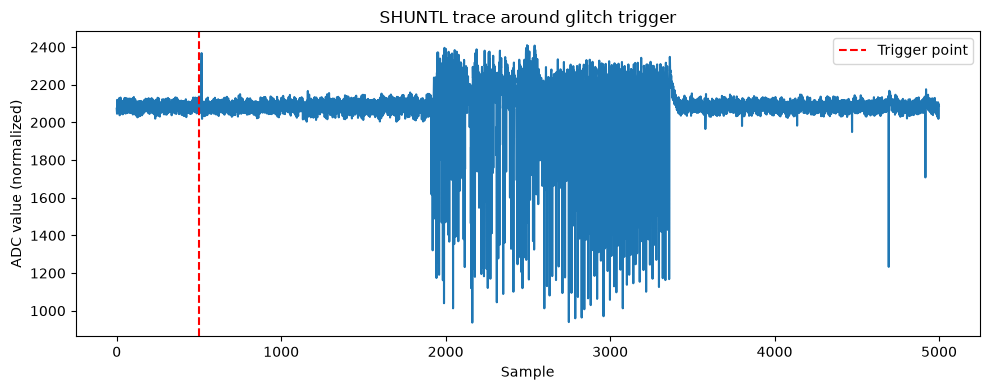

In [2]:
import chipwhisperer as cw
import time
import matplotlib.pyplot as plt

try:
    scope.dis()
except:
    pass

scope = cw.scope()

scope.gain.db = 20
scope.errors.clear()

# --- Clock setup ---
scope.clock.clkgen_freq = 7.37e6
scope.clock.adc_mul = 1
time.sleep(0.5)
assert scope.clock.clkgen_locked, "clkgen did not lock"

# --- Glitch module setup ---
scope.glitch.enabled = False
time.sleep(0.2)
scope.glitch.enabled = True
time.sleep(0.5)
scope.glitch.clk_src = 'pll'
scope.clock.fpga_vco_freq = 600e6
time.sleep(0.5)
assert scope.glitch.mmcm_locked, "glitch MMCM did not lock"

scope.io.glitch_trig_mcx = "glitch"

scope.glitch.output = "glitch_only"
scope.glitch.width = 500
scope.glitch.offset = 0
scope.glitch.repeat = 1

# --- Trigger: nRSTOUT via CW313 JP2 -> GPIO4/tio3 ---
scope.io.tio3 = "high_z"
scope.trigger.triggers = "tio3"
scope.adc.basic_mode = "rising_edge"
scope.glitch.trigger_src = "ext_single"

# --- ADC capture window around the glitch ---
# Capture enough samples to cover pre-trigger + the glitch pulse + a bit after.
# At adc_mul=1, ADC clock = clkgen_freq = 7.37 MHz -> 1 sample ≈ 135.7 ns
scope.adc.samples = 5000          # ~680 us total window, adjust as needed
scope.adc.offset = 0              # start capturing right at the trigger edge
scope.adc.presamples = 500        # samples captured *before* the trigger, to see baseline

# --- Crowbar MOSFET paths ---
scope.io.glitch_hp = True
scope.io.glitch_lp = True

print(scope.glitch)

# --- Fire once, capture ADC trace around the glitch, and plot it ---
print("Arming and firing a single glitch, capturing ADC trace on SHUNTL...")

scope.io.nrst = 'low'
time.sleep(0.05)
scope.arm()
time.sleep(0.01)
scope.io.nrst = 'high'

ret = scope.capture()
if ret:
    print("Timeout — no trigger seen, no trace captured")
else:
    trace = scope.get_last_trace()
    print(f"Captured {len(trace)} samples")

    plt.figure(figsize=(10, 4))
    plt.plot(trace)
    plt.axvline(x=scope.adc.presamples, color='r', linestyle='--', label='Trigger point')
    plt.xlabel("Sample")
    plt.ylabel("ADC value (normalized)")
    plt.title("SHUNTL trace around glitch trigger")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [3]:
print("scope.io.target_pwr: ", scope.io.target_pwr)
print("scope.io.glitch_hp: ", scope.io.glitch_hp)
print("scope.io.glitch_lp: ", scope.io.glitch_lp)
print("\nscope.gain.db: ", scope.gain.db)
print("\nscope.glitch:\n", scope.glitch)
print("\nscope.errors: \n", scope.errors)
print("scope.adc.errors: ", scope.adc.errors)

scope.io.target_pwr:  True
scope.io.glitch_hp:  True
scope.io.glitch_lp:  True

scope.gain.db:  20.045871559633028

scope.glitch:
 enabled           = True
num_glitches      = 1
clk_src           = pll
mmcm_locked       = True
width             = 500
offset            = 0
trigger_src       = ext_single
arm_timing        = after_scope
ext_offset        = 0
repeat            = 1
output            = glitch_only
phase_shift_steps = 4592


scope.errors: 
 sam_errors      = False
sam_led_setting = Default
XADC errors     = False
ADC errors      = False
extclk error    = False
trace errors    = False

scope.adc.errors:  False
